In [ ]:
# M1 : Z -> X, Z -> Y, X -> Y

# Step 1 : Draw out the DAG 

# Z causes X and Y 
# X causes Y 
# Z is binary ( 1 / 0 ) 

# Step 2 : Specify probability distributions for each one 

# Z follows a Bernoulli distibution 
# The are no arrows into Z so we define the marginal probability to be  P ( Z = 1 ) = 0.3 
#  When its parent Z is set to 0, we define the reference probability as P ( X = 1 | Z = 0 ) = 0. 2 
# We define one reference probability when bpth parents X and Z are set to 0 P ( Y = 1 | X = 0 , Z = 0 ) = 0.1 

# Step 3 : Define the strenght of the effect of the arrows 

# We need to define the strenght of the arrows , we will define the effect of Z on X to be 0.4 , Z on Y 0.4 and X on y to be 0.2 

# Step 4 : Write out the equations that define each node . 

# When simulating binary variables without parents , the marginal probability of Z = 1 needs to specified as shown the following equation : 

# P ( Z = 1 ) = 0.3 

# When simulating binary variables with parents , the conditional probability of equaling needs to be specified using the reference
# porbability along with the strenght of relevant effects . 

# P ( X = 1 | Z = 0 ) = 0.2 + 0.4 * Z 
# P ( Y = 1 | X = 0 , Z = 0 ) =  0.1 + 0.2 * X + 0.4 * Z 

In [ ]:
# Μ2 : # X -> Y, Z -> Y

# Step 1: Draw the DAG

# X -> Y, Z -> Y
# X causes Y
# Z causes Y
# Y is a collider

# Step 2: Specify probability distributions for each node

# The are no arrows into X so we define the marginal probability of X = 1 to be P(X = 1) = 0.3
# For the same reason as X , for Z the are no arrows coming into it so , we set P(Z = 1) = 0.2
# There arrows from X to Y and from Z to Y , so X and Z are the parents of Y ( Y is a collider ) .
# We define the probability of Y = 1 when its parents X , Z are equal to 0 to be ,  P( Y = 1 | X = 0 , Z = 0) = 0.1 . 

# Step 3: Define the strength of the effect of the arrows

# We define the strength of the arrows :
# The effect of X on Y  (b1): RD_XY = 0.4
# The effect of Z on Y (b2): RD_ZY = 0.3

# Step 4: Write out the equations that define each node

# For the binary variables without parent the equation is ( the marginal probability ) :
# P(X = 1) = 0.3 
# P(Z = 1) = 0.2

#For the binary variable with parents , the conditional probability of equaling 1 needs to 
#be specified using the reference probability along with the strength of relevant effects , 
# so we have :

#P(Y = 1 | X, Z) = 0.1 + 0.4 * X + 0.3 *  Z


-------------------------------------------
n =  50
 M1 rd_zx : 0.39877212110472965
 M1 rd_xy : 0.20165439748923206
 M1 rd_zy : 0.40766142380065157
-------------------------------------------
 M2 rd_xy : 0.39431104643803344
 M2 rd_zy : 0.29068699457566716
-------------------------------------------
n =  100
 M1 rd_zx : 0.40294966587755177
 M1 rd_xy : 0.1987673317131538
 M1 rd_zy : 0.4028131083515891
-------------------------------------------
 M2 rd_xy : 0.40035280586323924
 M2 rd_zy : 0.30712975860032626
-------------------------------------------
n =  150
 M1 rd_zx : 0.39861446223356994
 M1 rd_xy : 0.20696719273797104
 M1 rd_zy : 0.40841627055069923
-------------------------------------------
 M2 rd_xy : 0.39380681667623774
 M2 rd_zy : 0.294379248244524
-------------------------------------------
n =  300
 M1 rd_zx : 0.4016212564409667
 M1 rd_xy : 0.19274931453934102
 M1 rd_zy : 0.4004351974483078
-------------------------------------------
 M2 rd_xy : 0.39560387595268004
 M2 rd_zy :

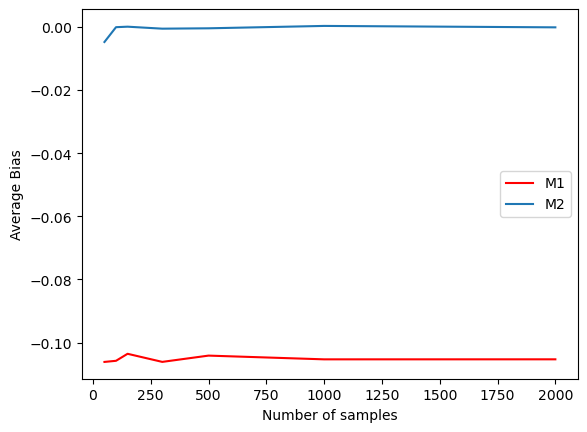

In [31]:
import numpy as np
import matplotlib.pyplot as plt 

np.random.seed(42)

def M1(n) : 

    Z = np.random.binomial( n = 1 , p = 0.3 , size = n ) 

    prob_X = 0.2 + 0.4 * Z 
    X = np.random.binomial( n = 1 , p = prob_X , size = n ) 

    prob_Y  = 0.1 + 0.2 * X + 0.4 * Z 
    Y = np.random.binomial( n = 1 , p = prob_Y , size = n ) 

    # Adjustment formula : P ( Y = 1 | do ( X = 1 ) ) = P ( Y = 1 | X = 1 , Z = 1 ) * P ( Z = 1 ) + P ( Y = 1 | X = 1 , Z = 0 ) * P ( Z = 0 ) 

    prob_Z1 = np.mean(Z) # P ( Z = 1 ) 
    prob_Z0 = 1 - prob_Z1  # P ( Z = 0 ) 

    prob_Y_given_X1_Z1 = np.mean ( Y [ ( X == 1 ) & ( Z == 1 ) ] )  # P ( Y = 1 | X = 1 , Z = 1 )
    prob_Y_given_X1_Z0 = np.mean ( Y [ ( X == 1 ) & ( Z == 0 ) ] )  # P ( Y = 1 | X = 1 , Z = 0 )

    prob_Y_do_X1 = ( prob_Y_given_X1_Z1 * prob_Z1 ) + ( prob_Y_given_X1_Z0 * prob_Z0 )
    prob_Y_X1 = np.mean(Y[X == 1])

    bias_M1 = prob_Y_do_X1 - prob_Y_X1  # bias = P(Y|do(X)) - P(Y|X) 
    
    # RD_ZX = P ( X = 1 | Z = 1 ) - P ( X = 1 | Z = 0 )
    rd_zx_M1 = np.mean(X[Z == 1]) - np.mean(X[Z == 0]) # 0.4
    
    # RD_XY = P ( Y = 1 | X = 1 , Z = 0 ) - P ( Y = 1 | X = 0 , Z = 0 )
    rd_xy_M1 = np.mean(Y[(X == 1) & (Z == 0)]) - np.mean(Y[(X == 0) & (Z == 0)]) # 0.2
    
    # RD_ZY = P ( Y = 1 | X = 0 , Z = 1 ) - P ( Y = 1 | X = 0 , Z = 0 )
    rd_zy_M1 = np.mean(Y[(X == 0) & (Z == 1)]) - np.mean(Y[(X == 0) & (Z == 0)]) # 0.4 
    
    return bias_M1,rd_zx_M1,rd_xy_M1,rd_zy_M1

#-------------------------------------------

def M2(n) : 
    X = np.random.binomial ( n = 1 , p = 0.3 , size = n ) # P ( X = 1 ) = 0.3 
    Z = np.random.binomial ( n = 1 , p = 0.2 , size = n ) # P ( Z = 1 ) = 0.2 
    
    prob_Y = 0.1 + 0.4 * X + 0.3 * Z   # we compute the probability for Y 
    Y = np.random.binomial ( n = 1 , p = prob_Y , size = n )  # P ( Y = 1 | X , Z )

    # P(Y = 1|do(X = 1)) = P(Y = 1|X = 1, Z = 1)P(Z = 1) + P(Y = 1|X = 1, Z = 0)P(Z = 0)  

    prob_Z1 = np.mean(Z) # P ( Z = 1 ) 
    prob_Z0 = 1 - prob_Z1  # P ( Z = 0 ) 

    prob_Y_given_X1_Z1 = np.mean ( Y [ ( X == 1 ) & ( Z == 1 ) ] )  # P ( Y = 1 | X = 1 , Z = 1 )
    prob_Y_given_X1_Z0 = np.mean ( Y [ ( X == 1 ) & ( Z == 0 ) ] )  # P ( Y = 1 | X = 1 , Z = 0 )

    prob_Y_do_X1 = ( prob_Y_given_X1_Z1 * prob_Z1 ) + ( prob_Y_given_X1_Z0 * prob_Z0 )
    prob_Y_X1 = np.mean(Y[X == 1])

    bias_M2 = prob_Y_do_X1 - prob_Y_X1  # bias = P(Y|do(X)) - P(Y|X)

    # RD_XY = P ( Y = 1 | X = 1 ) - P ( Y = 1 | X = 0 )
    rd_xy_M2 = np.mean(Y[X == 1]) - np.mean(Y[X == 0]) # 0.4

    # RD_ZY = P ( Y = 1 | Z = 1 ) - P ( Y = 1 | Z = 0 )
    rd_zy_M2 = np.mean(Y[Z == 1]) - np.mean(Y[Z == 0]) # 0.3
    
    return bias_M2,rd_xy_M2,rd_zy_M2
    
#-------------------------------------------

sample_size =  [ 50 , 100 ,150 , 300, 500 , 1000 , 2000]
iterations = 300 

# We want to verify that our code represents the DAG and the specified parameters . 
# We can verify this by computing the mean of the estimated risk differences and the results we get 
# are very close to the parameters that we specified which means that our code reproduces the DAG that we want . 

# For each sample size n, we create empty lists for each risk difference.
# Inside the loop of 300 iterations, we call M1(n) and M2(n) and append each value
# to its corresponding list based on its index position in the return statement.
# Finally, we compute and print the mean across the 300 iterations for each sample size.

for n in sample_size : 
    zx_1, xy_1, zy_1 = [], [], []
    xy_2, zy_2 = [], []

    for i in range(iterations):
        zx_1.append(M1(n)[1])
        xy_1.append(M1(n)[2])
        zy_1.append(M1(n)[3])
        
        xy_2.append(M2(n)[1])
        zy_2.append(M2(n)[2])
    
    print('-------------------------------------------')
    print ('n = ', n ) 
    print(' M1 rd_zx :', np.mean(zx_1)) # 0.4 
    print(' M1 rd_xy :', np.mean(xy_1)) # 0.2
    print(' M1 rd_zy :', np.mean(zy_1)) # 0.4
    print('-------------------------------------------')
    print(' M2 rd_xy :', np.mean(xy_2)) # 0.4
    print(' M2 rd_zy :', np.mean(zy_2)) # 0.3

# In this part, we compute the bias for both models. Using the same logic as before, for each sample 
# size n we create empty lists where we store the bias value returned at index [0] by M1(n) and M2(n) 
# across the 300 iterations. Finally, we compute the average bias for each sample size so that we can plot
# these results in our graph.

M1_bias = []
M2_bias = []

for n in sample_size:
    biases_1 = []
    biases_2 = []
    
    for i in range(iterations):
        biases_1.append(M1(n)[0])
        biases_2.append(M2(n)[0])
        
    M1_bias.append(np.nanmean(biases_1))
    M2_bias.append(np.nanmean(biases_2))

print('M1 bias :', M1_bias[0]) 
print('M2 bias :', M2_bias[0])
    
#-------------------------------------------

plt.figure()

plt.plot(sample_size, M1_bias, label='M1', color = 'red')
plt.plot(sample_size, M2_bias, label='M2')

plt.xlabel('Number of samples')
plt.ylabel('Average Bias')
plt.legend()
plt.show()